In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 47.3 MB/s  0:00:02


# Task 02 — House Rent Prediction (Regression)
**Goal:** predict the monthly rent of a house/apartment. **Target:** `Rent`. **Features:** BHK, Size, Bathroom, Area Type, Furnishing Status, City (Floor, Area Locality, Tenant Preferred, Point of Contact and Posted On are not used).

**Metrics:** MAE, MSE, RMSE and R². Because rent is very skewed we train on `log(Rent)` and always report the final errors in real rent units too.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import re
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Load the data

In [3]:
import os
path = 'dataset/House_Rent_Dataset.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'House_Rent_Dataset.csv'
df = pd.read_csv(path)

In [4]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [5]:
df.shape

(4746, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [7]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [8]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='object')

## 2. Data cleaning

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

In [11]:
df.reset_index(drop=True,inplace=True)

In [12]:
df.isnull().sum().sort_values(ascending=False).head()

,0
Size,8
Area Type,7
Rent,5
Bathroom,4
Posted On,0


**Missing values:** the old code filled `Rent` (the target!) and the other columns with the median of the *whole* data before splitting (data leakage). Now:
- `Rent` (target): rows removed.
- `Area Type`: missing -> category `Unknown`.
- `Size`, `Bathroom`: filled **after the split** with the median of the train data (next to the split).

In [13]:
# Rent is the TARGET: we do not fill it with a median, the 5 rows without Rent are removed
df = df.dropna(subset=['Rent']).reset_index(drop=True)

# 'Area Type' is categorical: a missing value becomes its own category (nothing is learned from the data)
df['Area Type'] = df['Area Type'].fillna('Unknown')

print("Rows:", len(df))

Rows: 4741


In [14]:
(df[['Size', 'Area Type', 'Rent', 'Bathroom']].isnull().sum())

,0
Size,6
Area Type,0
Rent,0
Bathroom,3


### Outliers (IQR rule)

Rent: 520 outliers (11.0%)  [valid range -24500 to 67500]  max = 3500000
Size: 203 outliers (4.3%)  [valid range -425 to 2175]  max = 8000
Bathroom: 232 outliers (4.9%)  [valid range -0 to 4]  max = 10
BHK: 27 outliers (0.6%)  [valid range 0 to 4]  max = 6


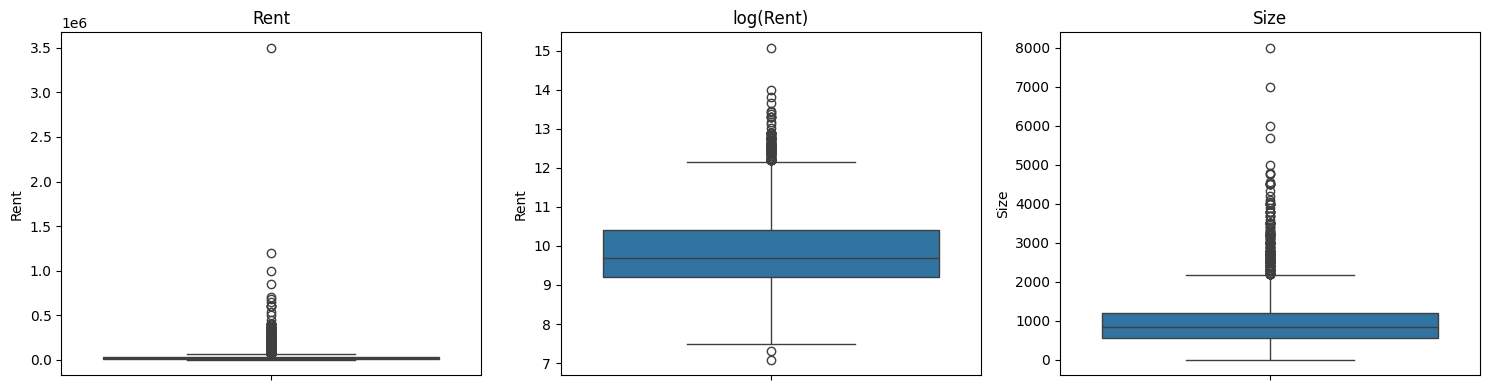

In [15]:
for col in ['Rent', 'Size', 'Bathroom', 'BHK']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(df) * 100:.1f}%)  [valid range {low:.0f} to {high:.0f}]  max = {df[col].max():.0f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df['Rent'], ax=axes[0]); axes[0].set_title('Rent')
sns.boxplot(y=np.log1p(df['Rent']), ax=axes[1]); axes[1].set_title('log(Rent)')
sns.boxplot(y=df['Size'], ax=axes[2]); axes[2].set_title('Size')
plt.tight_layout()
plt.show()

**Decision:** the extreme rents (up to millions) are real luxury properties, not typing errors, so the rows are **kept**. The problem is the skew: a few huge values dominate MSE/RMSE and make linear models weak. The log transformation of the target (used below) shrinks them and handles the outliers without deleting data. `Size` is a real measurement and is kept too.

## 3. EDA (visualization)

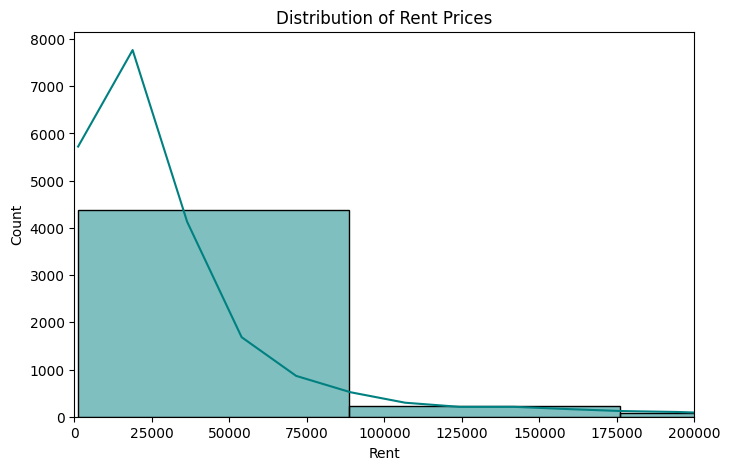

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Rent'], bins=40, kde=True, color='teal')
plt.title('Distribution of Rent Prices')
plt.xlabel('Rent')
plt.ylabel('Count')
plt.xlim(0, 200000)
plt.show()

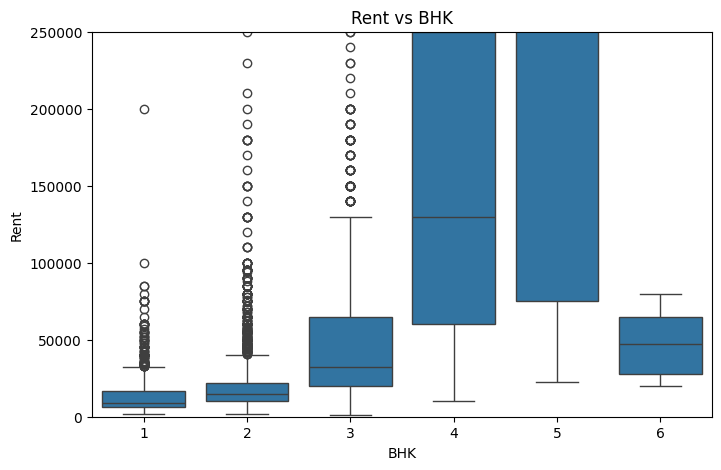

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='BHK', y='Rent', data=df)
plt.title('Rent vs BHK')
plt.xlabel('BHK')
plt.ylabel('Rent')
plt.ylim(0, 250000)
plt.show()

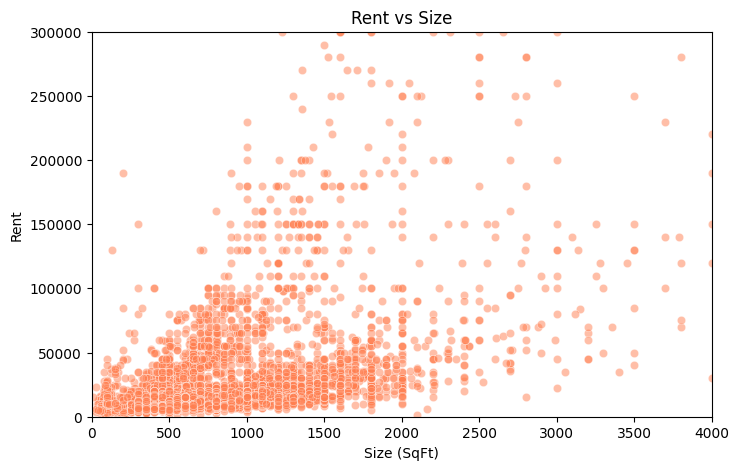

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Size', y='Rent', data=df, alpha=0.5, color='coral')
plt.title('Rent vs Size')
plt.xlabel('Size (SqFt)')
plt.ylabel('Rent')
plt.ylim(0, 300000)
plt.xlim(0, 4000)
plt.show()

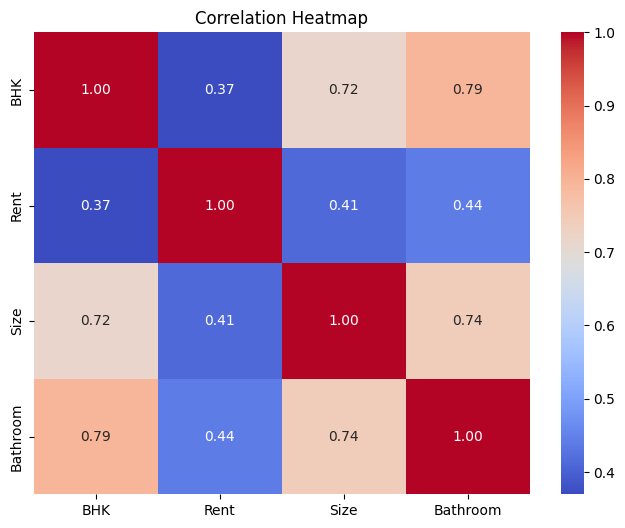

In [19]:
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 4. Encoding

In [20]:
categorical_cols = ['Area Type', 'Furnishing Status', 'City', 'Tenant Preferred', 'Point of Contact']

df_encoded = pd.get_dummies(df, columns=['Area Type', 'Furnishing Status', 'City'], drop_first=True)

print("Shape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)
df_encoded.head(2)

Shape before encoding: (4741, 12)
Shape after encoding: (4741, 19)


,Posted On,BHK,Rent,Size,Floor,Area Locality,Tenant Preferred,Bathroom,Point of Contact,Area Type_Carpet Area,Area Type_Super Area,Area Type_Unknown,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Bandel,Bachelors/Family,2.0,Contact Owner,False,True,False,False,True,False,False,False,True,False
1,5/13/2022,2,20000.0,NaN,1 out of 3,"Phool Bagan, Kankurgachi",Bachelors/Family,1.0,Contact Owner,False,True,False,True,False,False,False,False,True,False


In [21]:
X = df_encoded.drop(columns=['Rent', 'Posted On', 'Floor', 'Area Locality', 'Tenant Preferred', 'Point of Contact'], errors='ignore')
y = df_encoded['Rent']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4741, 13)
y shape: (4741,)


## 5. Train / Test split

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (3792, 13)
X_test shape: (949, 13)


### Fill missing `Size` and `Bathroom` (median of the train data only, then applied to test) -> no data leakage

In [23]:
X_train = X_train.copy()
X_test = X_test.copy()

imputer_X = SimpleImputer(strategy='median')
cols_to_fill = ['Size', 'Bathroom']
X_train[cols_to_fill] = imputer_X.fit_transform(X_train[cols_to_fill])
X_test[cols_to_fill] = imputer_X.transform(X_test[cols_to_fill])

print("Missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing values left: 0 0


## 6. Scaling (fit on train only)

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled X_train:", round(X_train_scaled.mean(), 5))
print("Std of scaled X_train:", round(X_train_scaled.std(), 5))

Mean of scaled X_train: -0.0
Std of scaled X_train: 1.0


## 7. Baseline: Linear Regression

In [25]:
from sklearn.linear_model import LinearRegression

In [26]:
model=LinearRegression(
    fit_intercept=True,
    copy_X=True,
    n_jobs=None,
    positive=False,
)

In [27]:
model.fit(X_train,y_train)

LinearRegression()

In [28]:
from  sklearn.metrics import mean_absolute_error , mean_squared_error,root_mean_squared_error,r2_score

In [29]:
y_pred = model.predict(X_test)

In [30]:
print("MAE : ",mean_absolute_error(y_test,y_pred))
print("MSE : ",mean_squared_error(y_test,y_pred))
print("RMSE : ",root_mean_squared_error(y_test,y_pred))
print("R2 : ",r2_score(y_test,y_pred))

MAE :  26907.161596862155
MSE :  14946210757.122828
RMSE :  122254.69625794678
R2 :  0.1563848606054039


### Log transformation of the target
Rent is very skewed. Training on log(Rent) should improve the result clearly (compare the R2 printed in the two cells).

In [31]:
# Rent is very skewed (a few luxury houses cost millions) -> train on log(Rent)
# Same split as before, only the target is transformed.
y_train_real, y_test_real = y_train.copy(), y_test.copy()
y_train = np.log1p(y_train_real)
y_test = np.log1p(y_test_real)

model.fit(X_train, y_train)
y_pred = np.expm1(model.predict(X_test))

print("R2 (real Rent):", r2_score(y_test_real, y_pred))
print("MAE (real Rent):", mean_absolute_error(y_test_real, y_pred))

R2 (real Rent): 0.2172415525661222
MAE (real Rent): 16465.555491881492


## 8. All the models
All models are trained on the (log) target. KNN and SVM use the scaled data.

In [32]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [33]:
from sklearn.linear_model import ElasticNet
models["ElasticNet"] = ElasticNet()

In [34]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [35]:
import time
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # لازم تتعمل بعد آخر train_test_split
X_test_scaled = scaler.transform(X_test)

models["SVM"] = SVR(kernel='rbf', C=10)

needs_scaling = {"SVM", "KNN"}
errors, times = {}, {}

for model_name, model in tqdm(models.items()):
    Xtr, Xte = (X_train_scaled, X_test_scaled) if model_name in needs_scaling else (X_train, X_test)

    start = time.time()
    model.fit(Xtr, y_train)
    times[model_name] = time.time() - start

    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, Xtr, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, Xte, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R_Train, "R2 Test": R_Test,
    }

pd.Series(times).sort_values(ascending=False)



 88%|████████▊ | 14/16 [00:14<00:01,  1.27it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005610 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 275
[LightGBM] [Info] Number of data points in the train set: 3792, number of used features: 12
[LightGBM] [Info] Start training from score 9.880178


100%|██████████| 16/16 [00:16<00:00,  1.01s/it]


,0
SVM,4.265345
ExtraTrees,2.009051
LightGBM,1.117598
Bagging,0.819129
GradientBoosting,0.781613
HistGradientBoosting,0.754238
Random Forest,0.684303
CatBoost,0.539105
XGBoost,0.492954
AdaBoost,0.140460


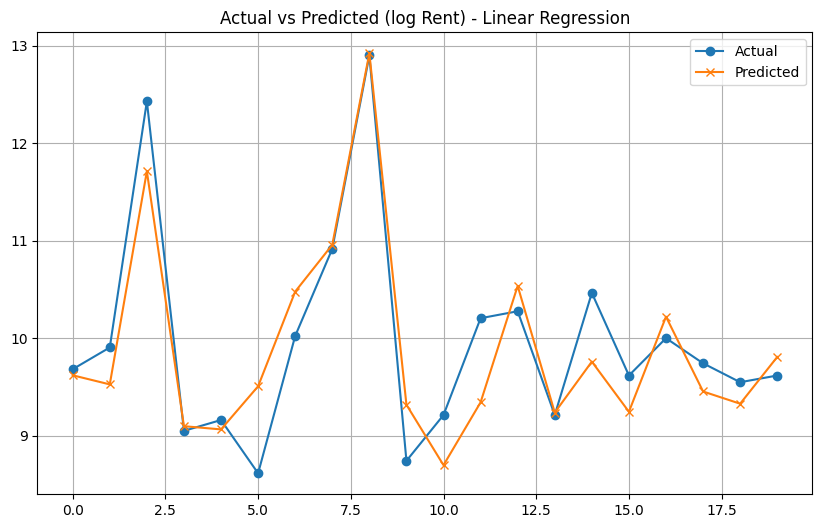

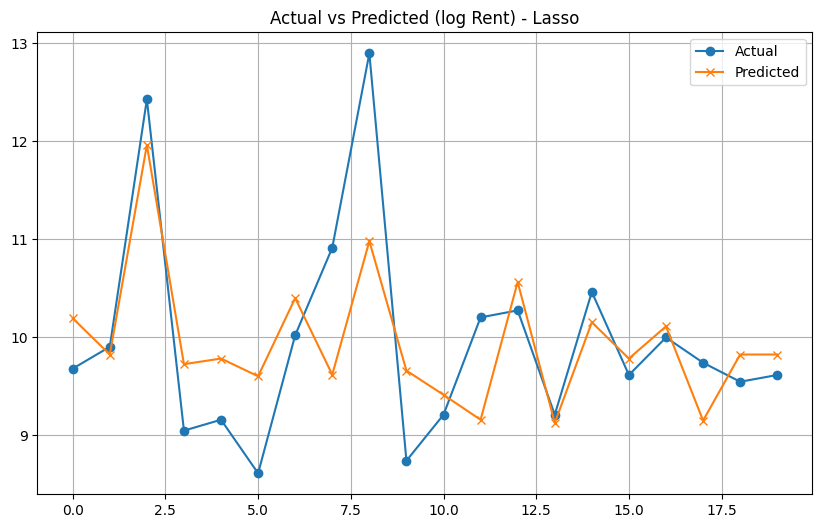

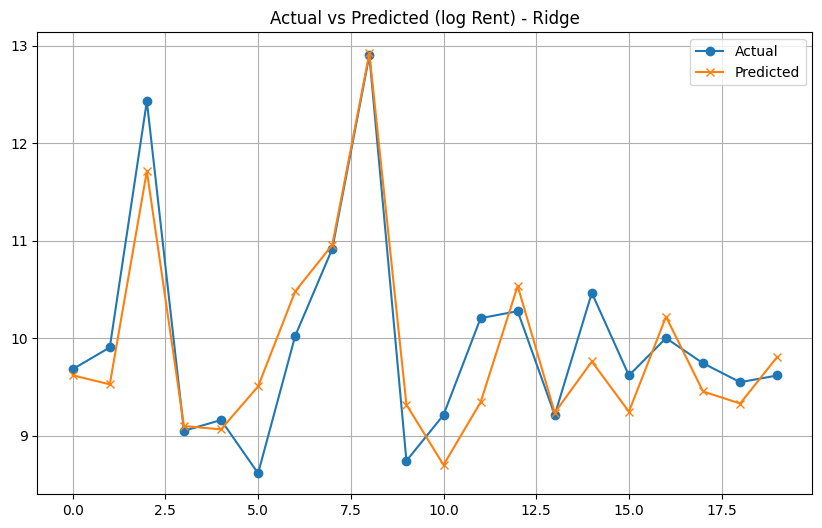

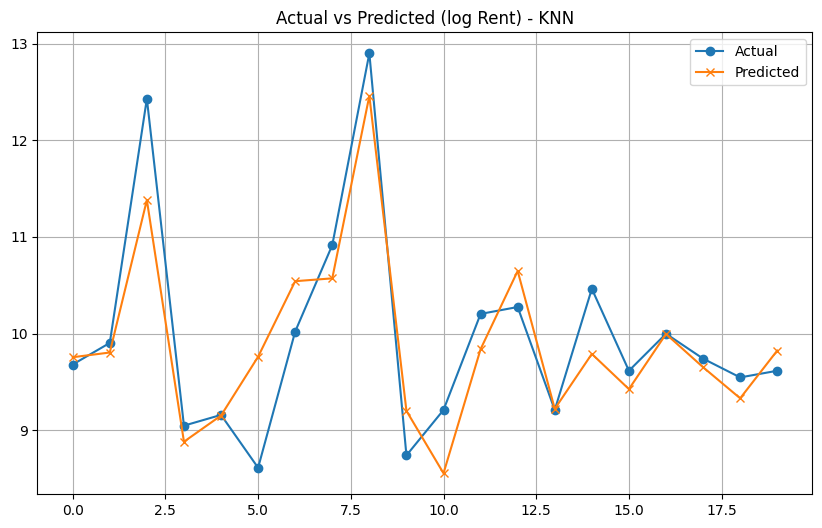

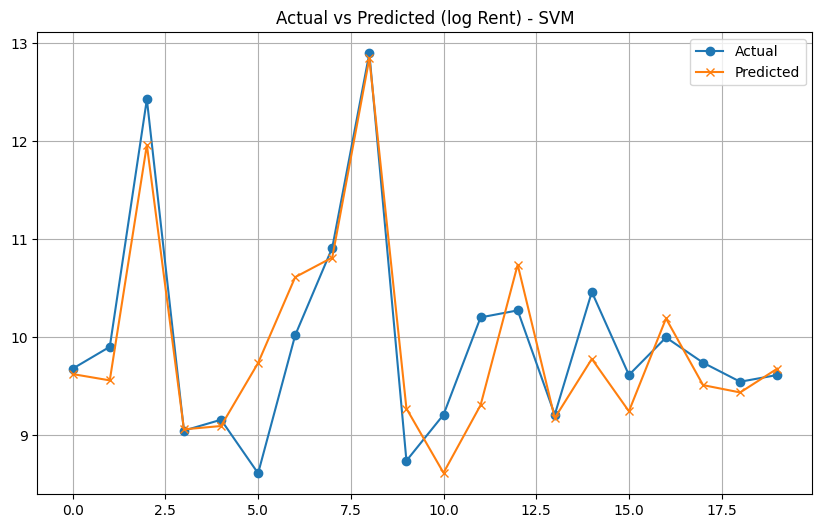

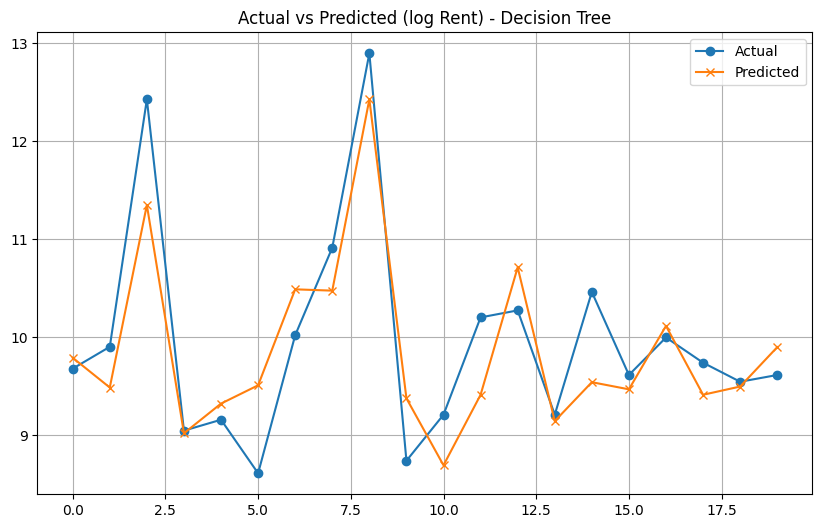

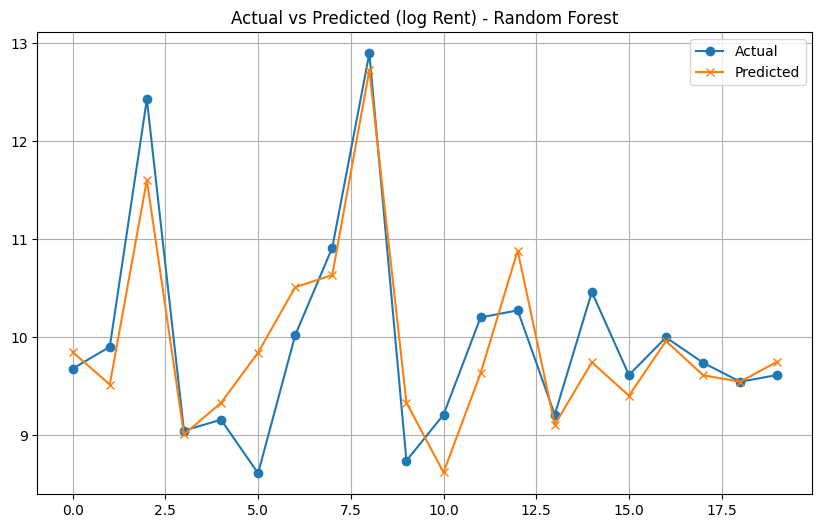

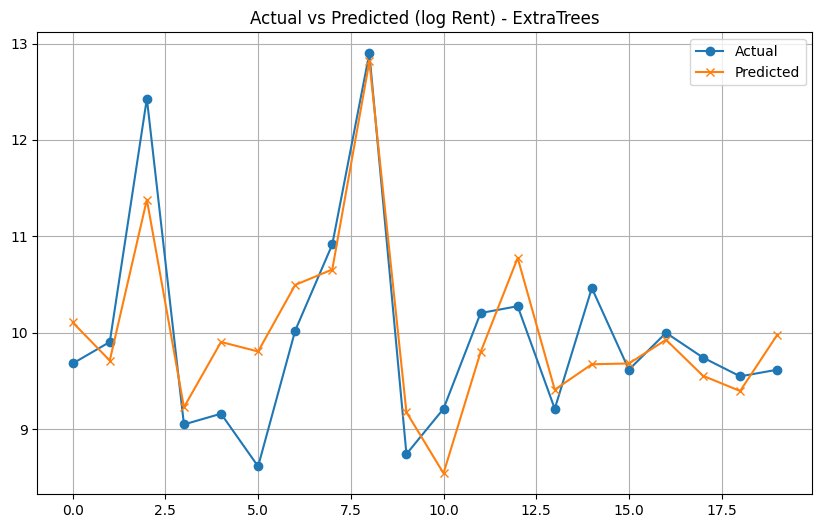

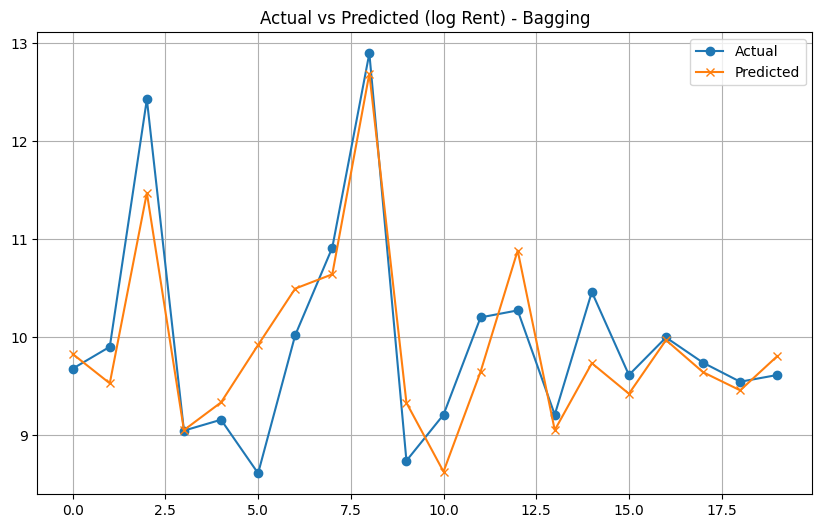

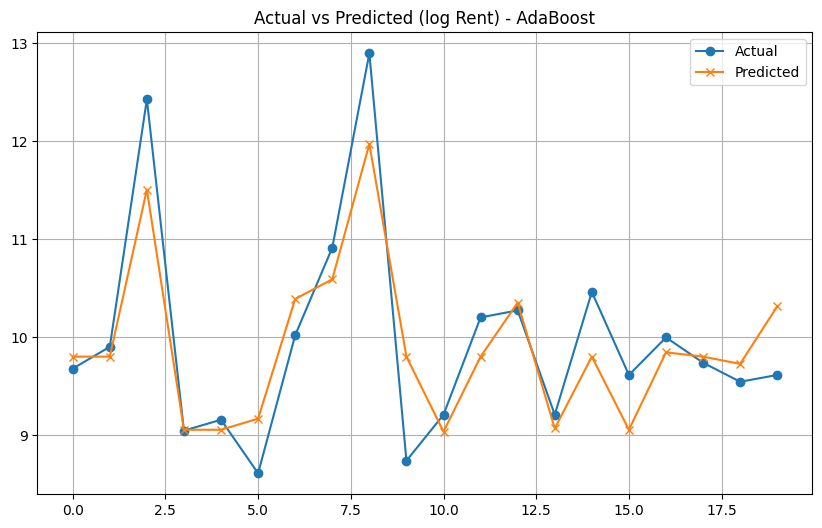

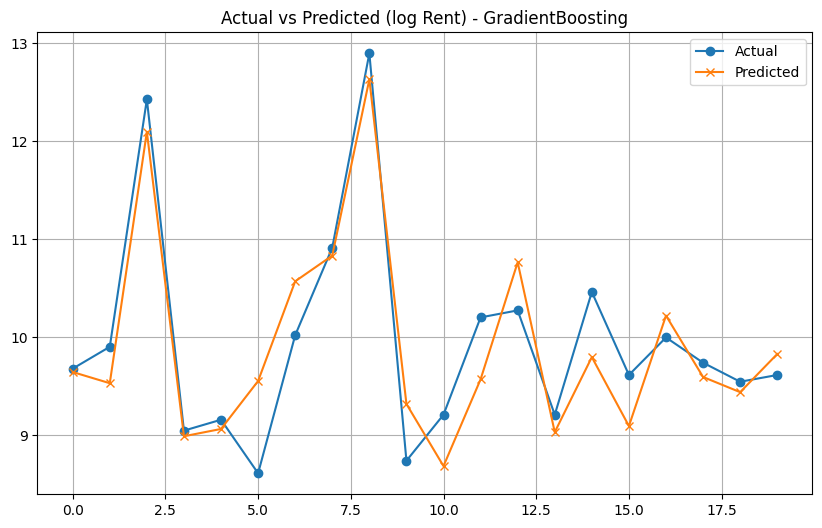

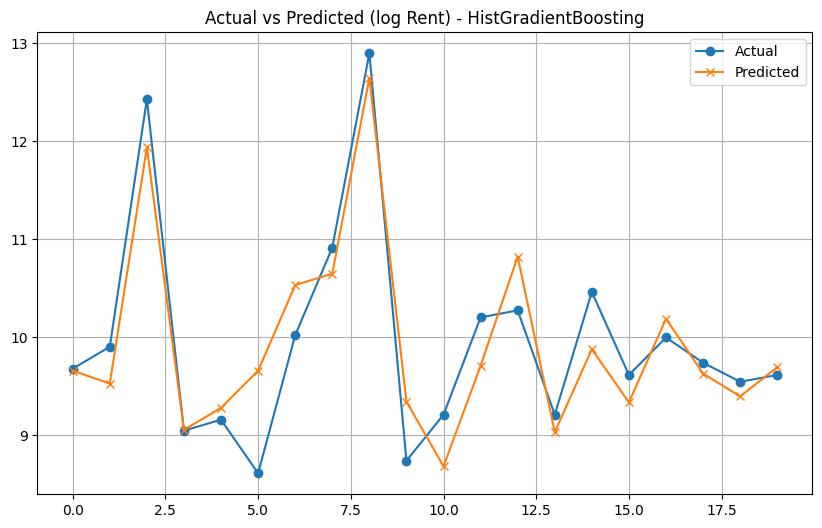

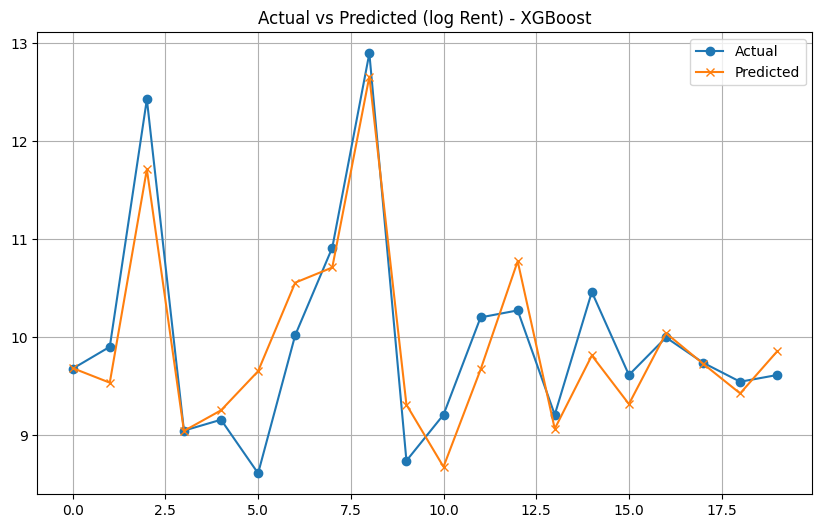

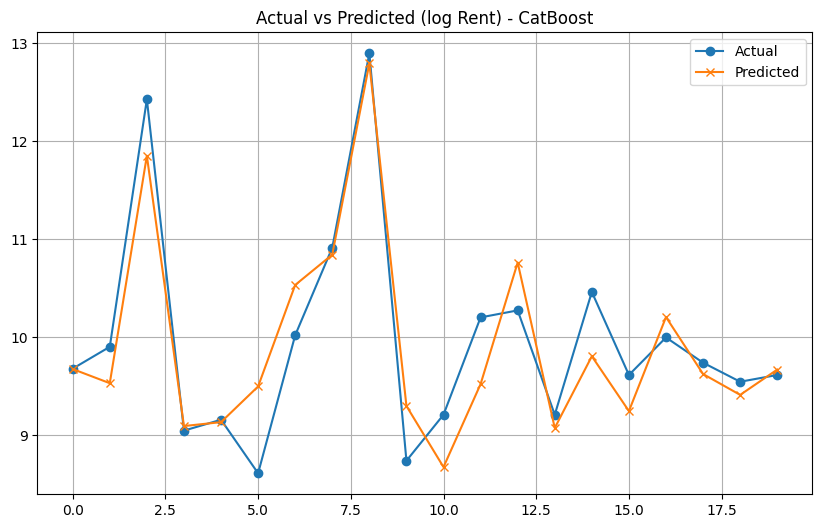

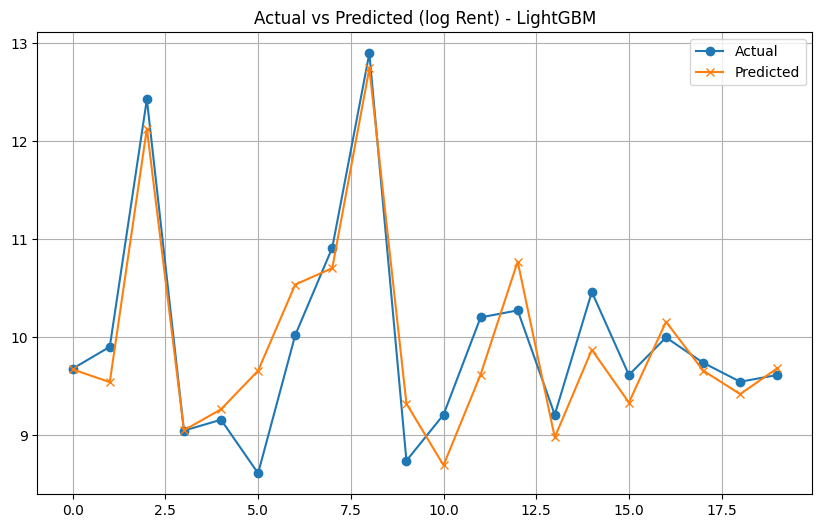

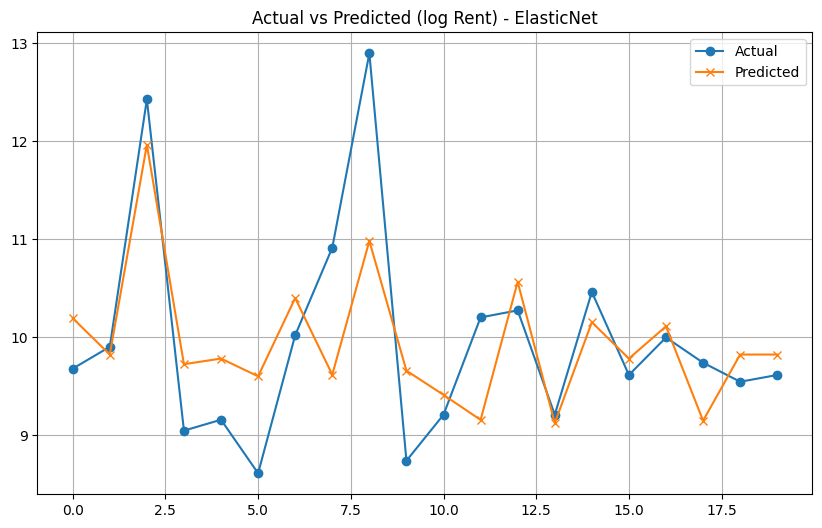

In [36]:
n = 20
for model_name, model in models.items():
    Xte = X_test_scaled if model_name in needs_scaling else X_test
    plt.figure(figsize=(10, 6))
    plt.plot(range(n), y_test.values[:n], label='Actual', marker='o')
    plt.plot(range(n), model.predict(Xte[:n]), label='Predicted', marker='x')
    plt.title('Actual vs Predicted (log Rent) - ' + model_name)
    plt.legend(); plt.grid()
    plt.show()

In [37]:
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1, n_jobs=-1)
clf3 = DecisionTreeRegressor(random_state=1)

voting = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
weighted_voting = VotingRegressor(
    estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=[2, 1, 2]
)

def add_result(name, mdl):
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(mdl, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(mdl, X_test, y_test)
    errors[name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train, "R2 Test": R2_Test,
    }

voting.fit(X_train, y_train)
add_result("Voting", voting)

weighted_voting.fit(X_train, y_train)
add_result("Weighted Voting", weighted_voting)

In [38]:
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [39]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [40]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
CatBoost,0.284560,0.308715,0.139961,0.193884,0.374113,0.440322,0.837308,0.794163
LightGBM,0.262163,0.308800,0.119546,0.194366,0.345755,0.440870,0.861038,0.793651
HistGradientBoosting,0.263905,0.307585,0.120332,0.194447,0.346889,0.440961,0.860124,0.793565
Bagging,0.232001,0.315879,0.090934,0.200317,0.301553,0.447568,0.894297,0.787333
GradientBoosting,0.285604,0.313783,0.141502,0.200890,0.376167,0.448208,0.835516,0.786724
Random Forest,0.232536,0.316967,0.091434,0.203121,0.302380,0.450689,0.893716,0.784356
XGBoost,0.246968,0.318184,0.104989,0.205846,0.324020,0.453703,0.877959,0.781463
Voting,0.192901,0.320142,0.067329,0.207436,0.259479,0.455452,0.921735,0.779775
Weighted Voting,0.197970,0.319601,0.070531,0.208607,0.265576,0.456735,0.918014,0.778532
SVM,0.268621,0.313644,0.131823,0.208866,0.363074,0.457018,0.846767,0.778257


<Axes: >

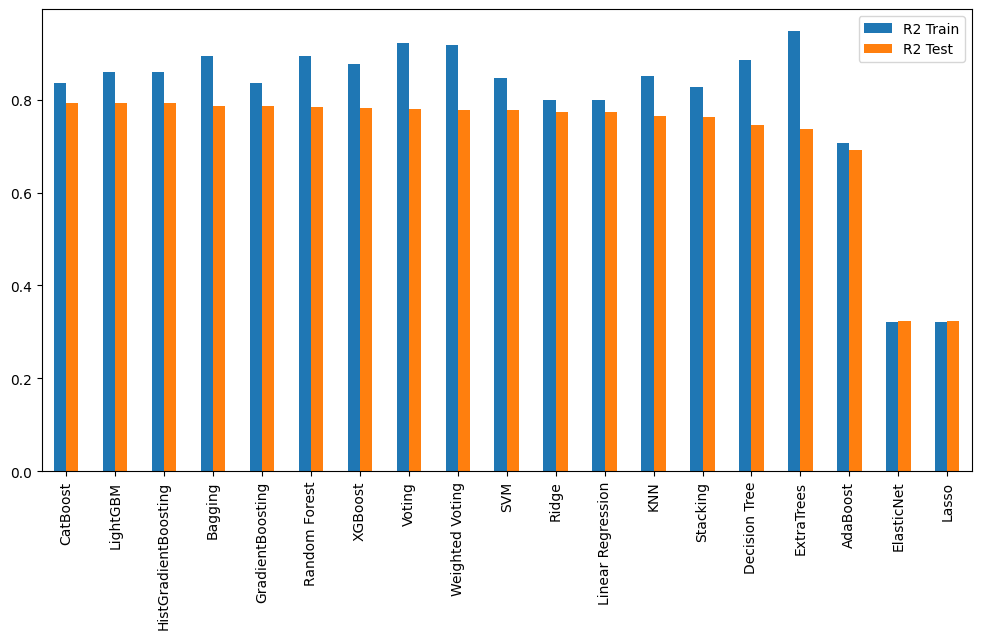

In [41]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

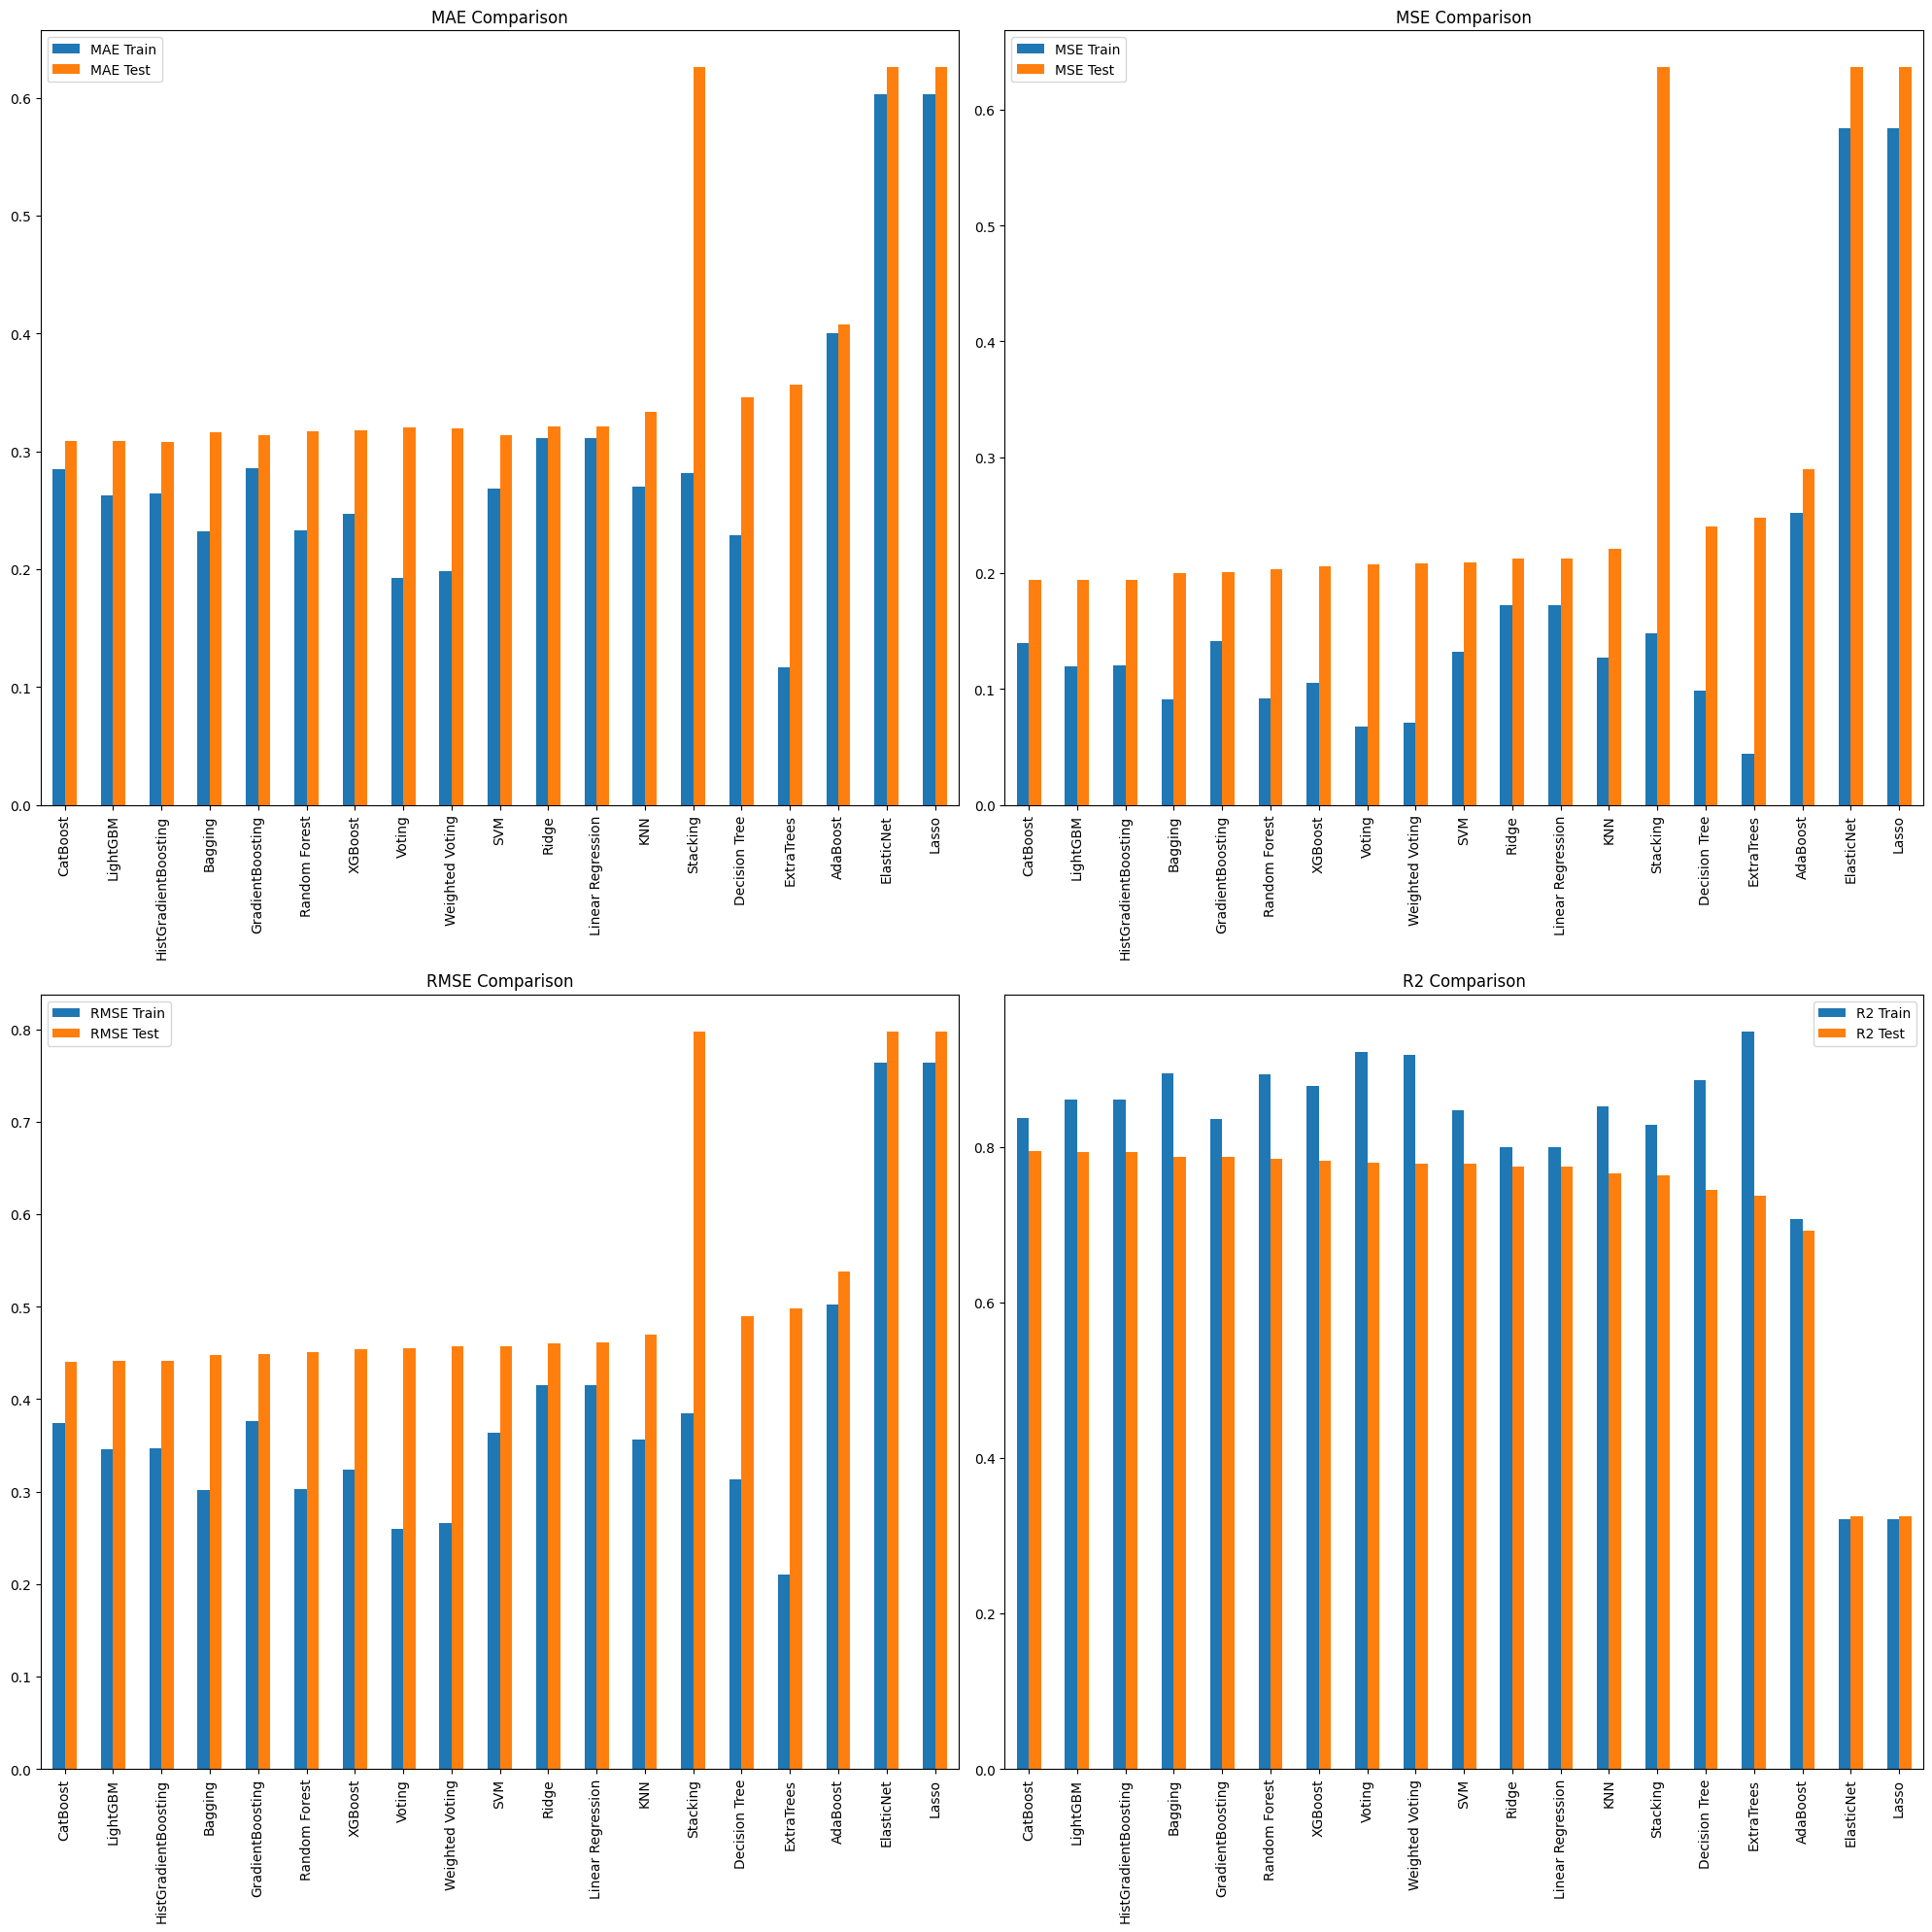

In [42]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** the table above uses the test set to show how each model behaves (errors are on the **log(Rent)** scale). To **choose** and **tune** the model we do not use the test set: we use cross-validation on the training data (next sections).

## 9. Model comparison with Cross-Validation (train data only)
5-fold cross-validation on the training data, metric **R²** (and RMSE on log(Rent)). KNN and SVM get a `StandardScaler` inside the pipeline, so the scaling is learned on each training fold only.

In [43]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def make_pipe(name, estimator):
    # scaler only for the models that need it
    scaler = StandardScaler() if name in needs_scaling else 'passthrough'
    return Pipeline([('scaler', scaler), ('model', clone(estimator))])

cv_rows = {}
for name, est in tqdm(models.items()):
    cv = cross_validate(make_pipe(name, est), X_train, y_train, cv=kf, n_jobs=-1,
                        scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    cv_rows[name] = {'CV R2': cv['test_r2'].mean(), 'CV RMSE (log)': -cv['test_rmse'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('CV R2', ascending=False)
cv_df

100%|██████████| 16/16 [00:17<00:00,  1.09s/it]


,CV R2,CV RMSE (log)
CatBoost,0.815011,0.397845
GradientBoosting,0.814483,0.398504
LightGBM,0.811818,0.401174
HistGradientBoosting,0.811733,0.401223
XGBoost,0.811071,0.402193
Bagging,0.801224,0.412521
SVM,0.799466,0.414258
Random Forest,0.799396,0.414374
Ridge,0.796192,0.417486
Linear Regression,0.796153,0.417529


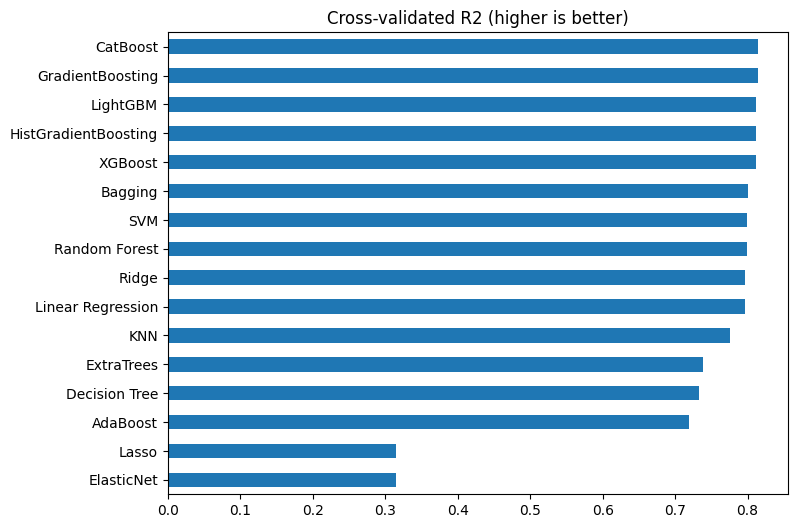

In [44]:
cv_df['CV R2'].sort_values().plot.barh(figsize=(8, 6))
plt.title('Cross-validated R2 (higher is better)')
plt.show()

**How to read it:** boosting / tree-ensemble models and Ridge-like linear models are usually the best here. A model with a big gap between its Train R² (table above) and its CV R² is overfitting (e.g. Decision Tree, ExtraTrees). Models with a very low CV R² (Lasso/ElasticNet with default strong regularization, AdaBoost) are not good candidates.

## 10. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold CV on the training data, metric R²). The test set is not used here.

In [45]:
param_grids = {
    'Linear Regression': {'model__fit_intercept': [True, False]},
    'Lasso': {'model__alpha': [0.0001, 0.001, 0.01, 0.1]},
    'Ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100]},
    'ElasticNet': {'model__alpha': [0.0001, 0.001, 0.01], 'model__l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'model__n_neighbors': [3, 5, 9, 15], 'model__weights': ['uniform', 'distance'], 'model__p': [1, 2]},
    'SVM': {'model__C': [1, 10, 100], 'model__epsilon': [0.01, 0.1]},
    'Decision Tree': {'model__max_depth': [5, 8, 12, None], 'model__min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'model__n_estimators': [100, 300], 'model__max_depth': [8, 12, None], 'model__min_samples_leaf': [1, 3]},
    'ExtraTrees': {'model__n_estimators': [100, 300], 'model__max_depth': [8, 12, None], 'model__min_samples_leaf': [1, 3]},
    'Bagging': {'model__n_estimators': [50, 100], 'model__max_samples': [0.7, 1.0]},
    'AdaBoost': {'model__n_estimators': [50, 100, 200], 'model__learning_rate': [0.05, 0.1, 0.5, 1.0]},
    'GradientBoosting': {'model__n_estimators': [100, 300], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 5]},
    'HistGradientBoosting': {'model__max_iter': [100, 300], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [None, 6]},
    'XGBoost': {'model__n_estimators': [200, 400], 'model__max_depth': [3, 5], 'model__learning_rate': [0.03, 0.1]},
    'CatBoost': {'model__iterations': [200, 500], 'model__depth': [4, 6], 'model__learning_rate': [0.05, 0.1]},
    'LightGBM': {'model__n_estimators': [200, 400], 'model__num_leaves': [15, 31], 'model__learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    grid = GridSearchCV(make_pipe(name, models[name]), param_grids[name], cv=kf, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV R2'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV R2)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['CatBoost', 'GradientBoosting', 'LightGBM']

CatBoost
  best_params_: {'model__depth': 4, 'model__iterations': 500, 'model__learning_rate': 0.05}
  best_score_ : 0.816

GradientBoosting
  best_params_: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300}
  best_score_ : 0.8157
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000468 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 275
[LightGBM] [Info] Number of data points in the train set: 3792, number of used features: 12
[LightGBM] [Info] Start training from score 9.880178

LightGBM
  best_params_: {'model__learning_rate': 0.03, 'model__n_estimators': 200, 'model__num_leaves': 15}
  best_score_ : 0.8165


,Before tuning (CV R2),After tuning (best_score_)
Model,,
CatBoost,0.815011,0.815978
GradientBoosting,0.814483,0.815725
LightGBM,0.811818,0.816525


**Why these parameters:** depth / leaf size / `alpha` control how complex the model is (overfitting vs underfitting); `learning_rate` and the number of trees trade off in boosting; `n_neighbors` and `weights` control the smoothness of KNN. The grids are small on purpose to keep the search fast and avoid tuning noise.

## 11. Final model and evaluation on the test set (used once)

In [46]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = tuned[best_name].best_estimator_
print("Best model:", best_name, tuned[best_name].best_params_)

pred_log = best_model.predict(X_test)
pred_real = np.expm1(pred_log)

results = pd.DataFrame({
    'log(Rent)': [mean_absolute_error(y_test, pred_log), mean_squared_error(y_test, pred_log),
                  np.sqrt(mean_squared_error(y_test, pred_log)), r2_score(y_test, pred_log)],
    'Real Rent': [mean_absolute_error(y_test_real, pred_real), mean_squared_error(y_test_real, pred_real),
                  np.sqrt(mean_squared_error(y_test_real, pred_real)), r2_score(y_test_real, pred_real)],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
results

Best model: LightGBM {'model__learning_rate': 0.03, 'model__n_estimators': 200, 'model__num_leaves': 15}


,log(Rent),Real Rent
MAE,0.308896,1.579767e+04
MSE,0.195136,1.399397e+10
RMSE,0.441742,1.182961e+05
R2,0.792833,2.101328e-01


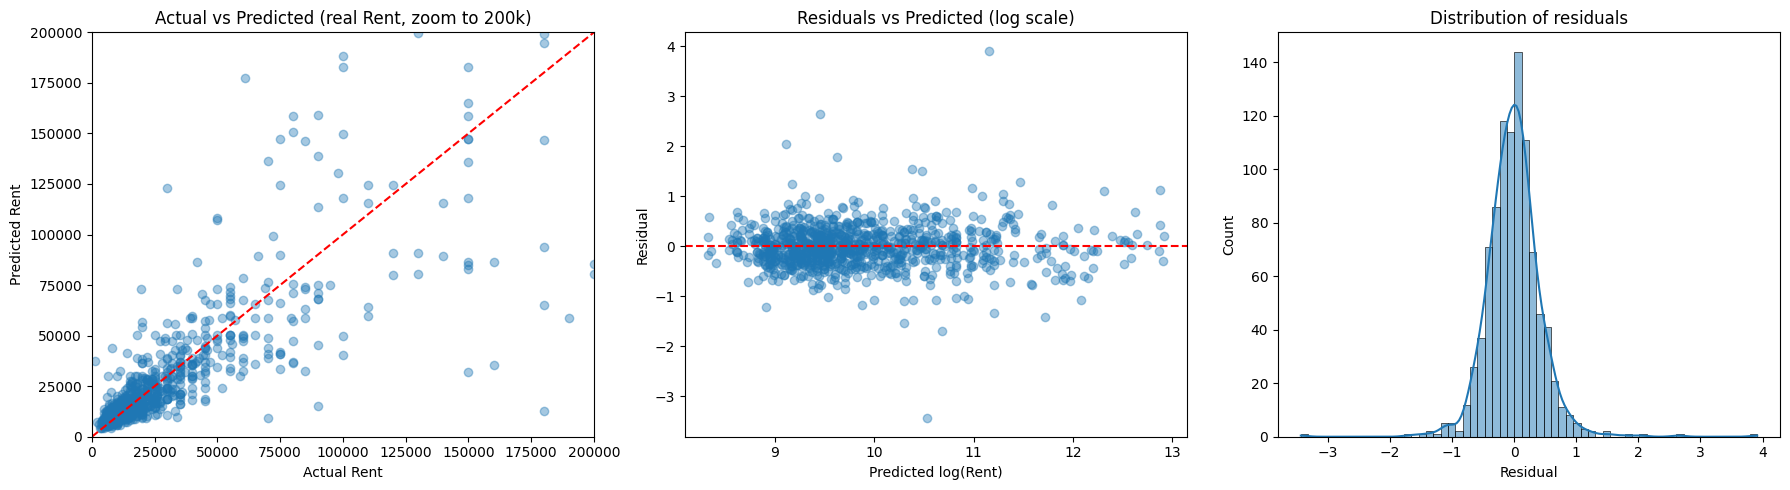

In [47]:
residuals = y_test - pred_log          # on the log scale
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_test_real, pred_real, alpha=0.4)
lim = [0, 200000]
axes[0].plot(lim, lim, 'r--'); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_title('Actual vs Predicted (real Rent, zoom to 200k)')
axes[0].set_xlabel('Actual Rent'); axes[0].set_ylabel('Predicted Rent')

axes[1].scatter(pred_log, residuals, alpha=0.4)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Residuals vs Predicted (log scale)')
axes[1].set_xlabel('Predicted log(Rent)'); axes[1].set_ylabel('Residual')

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_title('Distribution of residuals')
axes[2].set_xlabel('Residual')
plt.tight_layout()
plt.show()

In [48]:
errors_pct = np.abs(pred_real - y_test_real) / y_test_real * 100
print("=== Automatic interpretation of the results ===")
print(f"- Selected model: {best_name}.")
print(f"- On log(Rent): R2 = {results.loc['R2', 'log(Rent)']:.2f} -> the model explains {results.loc['R2', 'log(Rent)']:.0%} of the variation of the (log) rent.")
print(f"- Typical error: median absolute error = {np.median(np.abs(pred_real - y_test_real)):,.0f} per month "
      f"({np.median(errors_pct):.0f}% of the real rent); MAE = {results.loc['MAE', 'Real Rent']:,.0f}.")
print(f"- R2 on the real rent scale = {results.loc['R2', 'Real Rent']:.2f}; RMSE = {results.loc['RMSE', 'Real Rent']:,.0f} "
      "(pushed up by a few very expensive houses).")
cheap = (y_test_real < y_test_real.quantile(0.99)).values
print(f"- Without the 1% most expensive houses of the test set, R2 on the real rent = {r2_score(y_test_real[cheap], pred_real[cheap]):.2f}: "
      "a handful of luxury houses decides the real-scale R2, which is why the log-scale R2 is the more reliable number.")
print(f"- Mean residual (log) = {residuals.mean():.3f} (close to 0 means no systematic over/under prediction).")

=== Automatic interpretation of the results ===
- Selected model: LightGBM.
- On log(Rent): R2 = 0.79 -> the model explains 79% of the variation of the (log) rent.
- Typical error: median absolute error = 3,687 per month (23% of the real rent); MAE = 15,798.
- R2 on the real rent scale = 0.21; RMSE = 118,296 (pushed up by a few very expensive houses).
- Without the 1% most expensive houses of the test set, R2 on the real rent = 0.75: a handful of luxury houses decides the real-scale R2, which is why the log-scale R2 is the more reliable number.
- Mean residual (log) = -0.008 (close to 0 means no systematic over/under prediction).


**Interpretation**
- **R² (log scale)** is the best summary here: it measures the relative error and is not dominated by luxury properties.
- **MAE** is the average error in rent units; the **median** error is a fairer "typical" error because a few expensive houses inflate the mean.
- **RMSE / MSE** are larger than MAE because they square the errors of the expensive houses.
- **Actual vs Predicted:** points near the red diagonal are good predictions; the cloud widens for expensive houses (harder to predict, few examples).
- **Residuals vs Predicted:** a random cloud around 0 is what we want. A curve or funnel would show that the model misses a pattern or that errors grow with the rent.
- **Histogram of residuals:** roughly bell-shaped and centred on 0 means the errors are balanced.
- **Limits:** Floor, Area Locality and Posted On were not used. The neighborhood (`Area Locality`) is a strong driver of rent in real life and could improve the model.

## 12. Conclusions
- Missing values were handled without data leakage (the target is never imputed, the medians come from the train data only).
- The log transformation of the target is what makes the models work on this very skewed price; the results are reported both on the log and on the real scale.
- The final model was chosen with cross-validation, tuned with `GridSearchCV`, and evaluated on the test set only once.
- Possible improvements: use `Area Locality` and `Floor` (e.g. extract the floor number), add more data, try target encoding for the city/locality.